# Chapitre 12 - Cours 3 : observer l'état dérivé

Les cours 1 et 2 ont décrit comment les données dérivées sont **produites** et tenues à
jour. Ce notebook regarde l'autre bout : comment elles sont **lues**. Il couvre la
section *Observing Derived State* : la frontière entre chemin d'écriture et chemin de
lecture, les caches et vues matérialisées, les clients qui gardent un état local, la
diffusion des changements jusqu'à l'écran, les lectures traitées comme des événements
et les requêtes qui traversent plusieurs partitions.

**Plan.**

1. Chemin d'écriture et chemin de lecture.
2. Vues matérialisées et caches : déplacer la frontière.
3. Des clients avec état, capables de travailler hors ligne.
4. Pousser les changements jusqu'aux clients.
5. Les lectures sont aussi des événements.
6. Traitement de données multi-partition.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
SHARDS = "partitions"

## 1. Chemin d'écriture et chemin de lecture (section *Observing Derived State*)

Un système de flux de données est un procédé pour créer des jeux de données dérivés
(index, vues matérialisées, modèles prédictifs) et les tenir à jour. Le livre appelle ce
procédé le **chemin d'écriture** (write path) : une donnée écrite traverse plusieurs
étapes de traitement, et chaque jeu dérivé finit par l'intégrer. Mais si l'on crée un jeu
dérivé, c'est pour l'**interroger** : c'est le **chemin de lecture** (read path), qui lit
le jeu dérivé, le retravaille éventuellement, et construit la réponse.

Ensemble, les deux chemins couvrent tout le trajet de la donnée, de sa collecte à sa
consommation (par un humain, le plus souvent). Le chemin d'écriture est la partie
**précalculée**, faite dès l'arrivée de la donnée, que quelqu'un la demande ou non ; le
chemin de lecture n'a lieu **qu'à la demande**. En programmation fonctionnelle, on
parlerait d'évaluation **stricte** (eager) et **paresseuse** (lazy). Le jeu dérivé est le
lieu où les deux chemins **se rencontrent**.

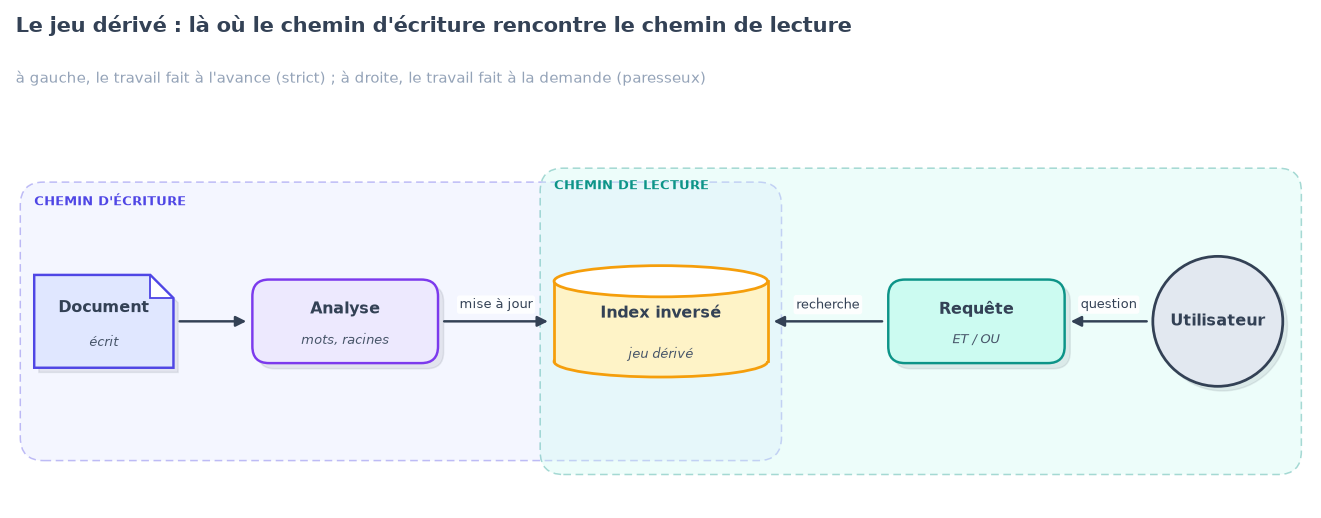

In [2]:
d = Diagram(14, 4.4, title="Le jeu dérivé : là où le chemin d'écriture rencontre le chemin de lecture",
            subtitle="à gauche, le travail fait à l'avance (strict) ; à droite, le travail fait à la demande (paresseux)")
d.box("doc", 1.0, 2.0, "Document", sub="écrit", color=INDIGO, kind="doc", w=1.5, h=1.0)
d.box("tok", 3.6, 2.0, "Analyse", sub="mots, racines", color=VIOLET, w=2.0)
d.box("idx", 7.0, 2.0, "Index inversé", sub="jeu dérivé", color=AMBER, kind="db", w=2.3, h=1.2)
d.box("q", 10.4, 2.0, "Requête", sub="ET / OU", color=TEAL, w=1.9)
d.box("u", 13.0, 2.0, "Utilisateur", kind="user", color=SLATE, w=1.4)
d.arrow("doc", "tok"); d.arrow("tok", "idx", "mise à jour")
d.arrow("q", "idx", "recherche"); d.arrow("u", "q", "question")
d.group(0.1, 0.5, 8.3, 3.5, "chemin d'écriture", color=INDIGO)
d.group(5.7, 0.35, 13.9, 3.65, "chemin de lecture", color=TEAL)
d.show()

> **À retenir.** Chemin d'écriture = travail précalculé dès l'arrivée des données ;
> chemin de lecture = travail fait à la demande. Tout jeu dérivé est un **compromis**
> entre ce qu'on fait à l'écriture et ce qu'on fait à la lecture.